In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [ ]:
# from google.colab import files
# data=files.upload()

In [ ]:
data=pd.read_csv("/content/DMart.csv")

**Data Understanding**

In [ ]:
display(data.head())

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs
0,Premia Badam (Almonds),Premia,451.0,329.0,Grocery,Grocery/Dry Fruits,500 gm,India,Grocery > Grocery/Dry Fruits
1,Premia Badam (Almonds),Premia,109.0,85.0,Grocery,Grocery/Dry Fruits,100 gm,India,Grocery > Grocery/Dry Fruits
2,Premia Badam (Almonds),Premia,202.0,175.0,Grocery,Grocery/Dry Fruits,200 gm,India,Grocery > Grocery/Dry Fruits
3,Nutraj California Almonds (Badam),Nutraj,599.0,349.0,Grocery,Dry Fruits,500 gm,USA,Grocery > Dry Fruits
4,Nutraj California Almonds (Badam),Nutraj,1549.0,659.0,Grocery,Dry Fruits,1 kg,USA,Grocery > Dry Fruits


In [ ]:
print("Dataset shape:", data.shape)

Dataset shape: (5189, 9)


In [ ]:
data["DiscountPercent"] = (
    (data["Price"] - data["DiscountedPrice"])
    * 100 /data["Price"]
)

In [ ]:
print(data.columns.tolist())

['Name', 'Brand', 'Price', 'DiscountedPrice', 'Category', 'SubCategory', 'Quantity', 'Description', 'BreadCrumbs', 'DiscountPercent']


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5189 entries, 0 to 5188
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             5188 non-null   object 
 1   Brand            4789 non-null   object 
 2   Price            5188 non-null   float64
 3   DiscountedPrice  5188 non-null   float64
 4   Category         5186 non-null   object 
 5   SubCategory      5186 non-null   object 
 6   Quantity         5188 non-null   object 
 7   Description      5187 non-null   object 
 8   BreadCrumbs      5186 non-null   object 
 9   DiscountPercent  5187 non-null   float64
dtypes: float64(3), object(7)
memory usage: 405.5+ KB


In [ ]:
print("Numerical columns:")
display(data.select_dtypes(include=np.number).columns.tolist())

print("Categorical columns:")
display(data.select_dtypes(include=["object", "category"]).columns.tolist())

Numerical columns:


['Price', 'DiscountedPrice', 'DiscountPercent']

Categorical columns:


['Name',
 'Brand',
 'Category',
 'SubCategory',
 'Quantity',
 'Description',
 'BreadCrumbs']

In [ ]:
missing = pd.DataFrame({
    "Missing_Count": data.isnull().sum()})
display(missing.sort_values("Missing_Count", ascending=False))

,Missing_Count
Brand,400
SubCategory,3
BreadCrumbs,3
Category,3
DiscountPercent,2
Description,2
Name,1
DiscountedPrice,1
Price,1
Quantity,1


In [ ]:
print("Total duplicate rows:", data.duplicated().sum())

Total duplicate rows: 0


In [ ]:
display(data.describe().T)

,count,mean,std,min,25%,50%,75%,max
Price,5188.0,344.030360,601.034092,0.0,85.000000,175.000000,345.00000,10990.0
DiscountedPrice,5188.0,236.669719,387.198716,0.0,64.000000,125.000000,249.00000,7999.0
DiscountPercent,5187.0,26.388023,15.181187,0.0,14.137931,22.292994,35.59515,98.0


In [ ]:
display(data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,5188,4360,Elle 18 Nail Pops Nail Colour - Shade 39,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,4789,822,Premia,155,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,5188.0,NaN,NaN,NaN,344.03036,601.034092,0.0,85.0,175.0,345.0,10990.0
DiscountedPrice,5188.0,NaN,NaN,NaN,236.669719,387.198716,0.0,64.0,125.0,249.0,7999.0
Category,5186,29,Personal Care,1234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubCategory,5186,86,Snacks & Farsans,302,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,5188,632,1 U,375,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,5187,3616,India,604,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BreadCrumbs,5186,97,Packaged Food > Snacks & Farsans,291,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DiscountPercent,5187.0,NaN,NaN,NaN,26.388023,15.181187,0.0,14.137931,22.292994,35.59515,98.0


In [ ]:
unique_counts = pd.DataFrame({
    "Unique_Values": data.nunique()
})
display(unique_counts.sort_values("Unique_Values"))

,Unique_Values
Category,29
SubCategory,86
BreadCrumbs,97
DiscountedPrice,613
Quantity,632
Price,636
Brand,822
DiscountPercent,1909
Description,3616
Name,4360


In [ ]:
print("=" * 40)
print("DMART DATASET - BASIC EDA SUMMARY")
print("=" * 40)

print(f"Total rows: {data.shape[0]:,}")
print(f"Total columns: {data.shape[1]:,}")
print(f"Duplicate rows: {data.duplicated().sum():,}")
print(f"Missing cells: {data.isnull().sum().sum():,}")
print(f"Numerical columns: {len(data.select_dtypes(include=np.number).columns)}")
print(f"Categorical/text columns: {len(data.select_dtypes(include=['object', 'category']).columns)}")

DMART DATASET - BASIC EDA SUMMARY
Total rows: 5,189
Total columns: 10
Duplicate rows: 0
Missing cells: 417
Numerical columns: 3
Categorical/text columns: 7


**Data Cleaning & Quality**

In [ ]:
# Create a copy for data cleaning
clean_data = data.copy()

print("Original dataset shape:", data.shape)
print("Working dataset shape:", clean_data.shape)

Original dataset shape: (5189, 10)
Working dataset shape: (5189, 10)


In [ ]:
clean_data.isnull().sum()

,0
Name,1
Brand,400
Price,1
DiscountedPrice,1
Category,3
SubCategory,3
Quantity,1
Description,2
BreadCrumbs,3
DiscountPercent,2


In [ ]:
clean_data['Name'] = clean_data['Name'].fillna('Kitchen Appliance')

In [ ]:
clean_data['Brand'] = clean_data['Brand'].fillna('Local/Unknown')

In [ ]:
clean_data[clean_data['Price'].isnull()==True]

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
4323,Elle 18 Nail Pops Nail Colour - Shade 125,Elle 18,NaN,NaN,Personal Care,Personal Care/Nail Care,5 ml,NaN,Personal Care > Personal Care/Nail Care,NaN


In [ ]:
clean_data.isnull().sum()

,0
Name,0
Brand,0
Price,1
DiscountedPrice,1
Category,3
SubCategory,3
Quantity,1
Description,2
BreadCrumbs,3
DiscountPercent,2


In [ ]:
clean_data['Price']=clean_data['Price'].fillna(clean_data[clean_data['SubCategory']=='Personal Care/Nail Care']['Price'].mean())

In [ ]:
clean_data['DiscountedPrice']=clean_data['DiscountedPrice'].fillna(clean_data[clean_data['SubCategory']=='Personal Care/Nail Care']['DiscountedPrice'].mean())

In [ ]:
clean_data[clean_data['Category'].isnull()==True]

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
3180,Stainless Steel Idli Maker with Lid,Keyur Kitchenware,900.0,499.0,NaN,NaN,1 Unit,\n- Container Material : Stainless Steel\n- Ha...,NaN,44.555556
3243,Pigeon ESS Non-Stick Gift Set - Red,Pigeon,2895.0,1359.0,NaN,NaN,7 pcs,\n-Specifications :\n- Coating : 5 Layers Non-...,NaN,53.056995
3245,Wonderchef Milano Set - Red,Wonderchef,4200.0,1999.0,NaN,NaN,4 Pcs,\n- Adorn your kitchen with this beautiful Mil...,NaN,52.404762


In [ ]:
clean_data['Category'] = clean_data['Category'].fillna('Home & KitchenAppliances')

In [ ]:
clean_data['SubCategory'] = clean_data['SubCategory'].fillna('Home Appliances')

In [ ]:
clean_data['BreadCrumbs']=clean_data['BreadCrumbs'].fillna('Home & Kitchen > Cookware & Serveware')

In [ ]:
clean_data[clean_data.Quantity.isnull()==True]

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
5047,Zeel MT212 Men's Raincoat - Navy Blue : Size XXL,Zeel,1199.0,1049.0,Raincoat,Raincoat,NaN,Specifications- Material : Fabric- Colour : Na...,Raincoat,12.510425


In [ ]:
clean_data['Quantity'] = clean_data['Quantity'].fillna('Size XXL')

In [ ]:
clean_data['Description'] = clean_data['Description'].fillna('No Desciption')

In [ ]:
clean_data['DiscountPercent'] = clean_data['DiscountPercent'].fillna(0)


In [ ]:
clean_data.isnull().sum()

,0
Name,0
Brand,0
Price,0
DiscountedPrice,0
Category,0
SubCategory,0
Quantity,0
Description,0
BreadCrumbs,0
DiscountPercent,0


In [ ]:
price_cols = ["Price", "DiscountedPrice"]

# Ensure both price columns are numeric
for col in price_cols:
    clean_data[col] = pd.to_numeric(
        clean_data[col], errors="coerce"
    )

valid_pairs = clean_data[price_cols].notna().all(axis=1)

print("Negative original prices:",
      (clean_data["Price"] < 0).sum())

print("Negative discounted prices:",
      (clean_data["DiscountedPrice"] < 0).sum())

print("Zero original prices:",
      (clean_data["Price"] == 0).sum())

print("Zero discounted prices:",
      (clean_data["DiscountedPrice"] == 0).sum())

print("Discounted price greater than original:",
      (
          valid_pairs &
          (clean_data["DiscountedPrice"] > clean_data["Price"])
      ).sum())

print("Exact duplicate rows:", clean_data.duplicated().sum())

print("\nMissing values by column:")
display(clean_data.isna().sum().to_frame("Missing_Count"))

Negative original prices: 0
Negative discounted prices: 0
Zero original prices: 1
Zero discounted prices: 1
Discounted price greater than original: 0
Exact duplicate rows: 0

Missing values by column:


,Missing_Count
Name,0
Brand,0
Price,0
DiscountedPrice,0
Category,0
SubCategory,0
Quantity,0
Description,0
BreadCrumbs,0
DiscountPercent,0


In [ ]:
print("=" * 45)
print("DMART DATA CLEANING - FINAL SUMMARY")
print("=" * 45)

print("Total rows:", len(clean_data))
print("Total columns:", len(clean_data.columns))
print("Duplicate rows:", clean_data.duplicated().sum())
print("Missing cells:", clean_data.isna().sum().sum())
print("Missing original prices:", clean_data["Price"].isna().sum())
print("Missing discounted prices:",
      clean_data["DiscountedPrice"].isna().sum())

print("\nNegative original prices:",
      (clean_data["Price"] < 0).sum())

print("Negative discounted prices:",
      (clean_data["DiscountedPrice"] < 0).sum())

print("Outlier records removed: 0")

DMART DATA CLEANING - FINAL SUMMARY
Total rows: 5189
Total columns: 10
Duplicate rows: 0
Missing cells: 0
Missing original prices: 0
Missing discounted prices: 0

Negative original prices: 0
Negative discounted prices: 0
Outlier records removed: 0


In [ ]:
clean_data.head()

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
0,Premia Badam (Almonds),Premia,451.0,329.0,Grocery,Grocery/Dry Fruits,500 gm,India,Grocery > Grocery/Dry Fruits,27.050998
1,Premia Badam (Almonds),Premia,109.0,85.0,Grocery,Grocery/Dry Fruits,100 gm,India,Grocery > Grocery/Dry Fruits,22.018349
2,Premia Badam (Almonds),Premia,202.0,175.0,Grocery,Grocery/Dry Fruits,200 gm,India,Grocery > Grocery/Dry Fruits,13.366337
3,Nutraj California Almonds (Badam),Nutraj,599.0,349.0,Grocery,Dry Fruits,500 gm,USA,Grocery > Dry Fruits,41.736227
4,Nutraj California Almonds (Badam),Nutraj,1549.0,659.0,Grocery,Dry Fruits,1 kg,USA,Grocery > Dry Fruits,57.456423


Column Cleaning

In [ ]:
clean_data['DiscountPercent']=clean_data['DiscountPercent'].apply(lambda x:int(x))

In [ ]:
clean_data.head()

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
0,Premia Badam (Almonds),Premia,451.0,329.0,Grocery,Grocery/Dry Fruits,500 gm,India,Grocery > Grocery/Dry Fruits,27
1,Premia Badam (Almonds),Premia,109.0,85.0,Grocery,Grocery/Dry Fruits,100 gm,India,Grocery > Grocery/Dry Fruits,22
2,Premia Badam (Almonds),Premia,202.0,175.0,Grocery,Grocery/Dry Fruits,200 gm,India,Grocery > Grocery/Dry Fruits,13
3,Nutraj California Almonds (Badam),Nutraj,599.0,349.0,Grocery,Dry Fruits,500 gm,USA,Grocery > Dry Fruits,41
4,Nutraj California Almonds (Badam),Nutraj,1549.0,659.0,Grocery,Dry Fruits,1 kg,USA,Grocery > Dry Fruits,57


In [ ]:
# Quantity Column Cleaning:


# Display all unique Quantity values
quantity_values = clean_data["Quantity"].dropna().unique()

print("Total unique Quantity values:", len(quantity_values))

for value in sorted(quantity_values, key=str):
    print(value)

Total unique Quantity values: 632
 1 L
 5 kg
 50 gm
 5x125 gm
 6 Pcs
0.35 gm
0.5 Watts
0.6 ml
0.7 gm
1 Book
1 Kg
1 L
1 L x 12 U
1 Litre
1 U
1 Unit
1 Wipe
1 gm
1 kg
1 ml
1 pc
1.1 Litre
1.2 Kg
1.2 L
1.2 gm
1.2 kg
1.2 ml
1.24 kg
1.25 Kg
1.25 L
1.25 kg
1.3 L
1.3 gm
1.4 gm
1.5 L
1.5 Litres
1.5 gm
1.5 kg
1.6 L
1.7 gm
1.75 L
1.8 L
1.8 Litres
10 Bags
10 L
10 Pcs
10 Pieces
10 U
10 W
10 Watts
10 Wipes
10 gm
10 kg
10 ml
10 ml + 10 ml
10 x 12 Inches
100 Bags
100 Pcs
100 U
100 gm
100 ml
100.8 gm
1000 W
104 gm
105 gm
106 U
107 gm
108 U
108 gm
108.5 gm
11 gm
110 gm
110 ml
115 gm
115 ml
117 gm
119 gm
12 Pcs
12 Shades
12 U
12 W
12 Watts
12 gm
120 Tablets
120 U
120 gm
120 ml
1200 gm
121
124 gm
125 W
125 gm
125 ml
126 gm
129
12x16.5 gm
13 ml
130 U
130 gm
130 ml
130.9 gm
132 gm
135 gm
136 gm
137 gm
137.5 gm
138 gm
139.2 gm
14 Shades
14 Watts
14 gm
140 gm
1400 W
142.2 gm
143 gm
145 gm
148 gm
14x10.8 gm
15 L
15 Pcs
15 U
15 gm
15 ml
15.8 gm
150 gm
150 ml
153 gm
154 ml
156 gm
159 gm
16 Bags
16 U
16 gm
160 gm


In [ ]:
# 1. Standardize whitespace
clean_data["Quantity"] = (
    clean_data["Quantity"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# 2. Standardize measurement units
clean_data["Quantity"] = (
    clean_data["Quantity"]
    .str.replace(r"\bkg\b", "kg", case=False, regex=True)
    .str.replace(r"\bgm\b", "gm", case=False, regex=True)
    .str.replace(r"\bml\b", "ml", case=False, regex=True)
    .str.replace(r"\blitres?\b", "L", case=False, regex=True)
    .str.replace(r"\bliters?\b", "L", case=False, regex=True)
)

# 3. Standardize Unit / Units to U
clean_data["Quantity"] = clean_data["Quantity"].str.replace(
    r"^(\d+(?:\.\d+)?)\s*Units?$",
    r"\1 U",
    case=False,
    regex=True
)

# 4. Standardize Pcs / Pieces to pc
clean_data["Quantity"] = clean_data["Quantity"].str.replace(
    r"^(\d+(?:\.\d+)?)\s*(?:pcs|pieces)$",
    r"\1 pc",
    case=False,
    regex=True
)

# 5. Standardize Watts / Watt to W
clean_data["Quantity"] = clean_data["Quantity"].str.replace(
    r"^(\d+(?:\.\d+)?)\s*Watts?$",
    r"\1 W",
    case=False,
    regex=True
)

# 6. Standardize Pack / Set capitalization
clean_data["Quantity"] = (
    clean_data["Quantity"]
    .str.replace(r"\bpack of\b", "Pack of", case=False, regex=True)
    .str.replace(r"\bset of\b", "Set of", case=False, regex=True)
)

# 7. Standardize multiplication separator spacing
clean_data["Quantity"] = (
    clean_data["Quantity"]
    .str.replace(r"\s*[xX]\s*", " x ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# 8. Restore clothing sizes affected by multiplication formatting
clean_data["Quantity"] = clean_data["Quantity"].replace({
    "Size x L": "Size XL",
    "Size x x L": "Size XXL",
    "Size x x x L": "Size XXXL",
    "x L (95 cm)": "XL (95 cm)",
    "x x L (100 cm)": "XXL (100 cm)",
    "x x x L (105 cm)": "XXXL (105 cm)"
})

# 9. Standardize metre-related unit labels to m
clean_data["Quantity"] = (
    clean_data["Quantity"]
    .str.replace(r"\bmetres?\b", "m", case=False, regex=True)
    .str.replace(r"\bmeters?\b", "m", case=False, regex=True)
    .str.replace(r"\bmtr\b", "m", case=False, regex=True)
)

# 10. Verify the results
print("Total unique Quantity values:", clean_data["Quantity"].nunique())

display(
    clean_data[
        clean_data["Quantity"].str.contains(
            r"\bm\b", case=False, regex=True, na=False
        )
    ]["Quantity"]
    .value_counts()
    .sort_index()
    .to_frame("Count")
)

Total unique Quantity values: 587


,Count
Quantity,
22 cm x 20 M,1
24 x 50 m,1
30 cm x 20 m,1
30 cm x 3 M,1
30 cm x 5 M,1
4 m,1
5 m,1
6 m,1
72 m,1


In [ ]:
quantity_values = clean_data["Quantity"].dropna().unique()

print("Total unique Quantity values:", len(quantity_values))

for value in sorted(quantity_values, key=str):
    print(value)

Total unique Quantity values: 587
0.35 gm
0.5 W
0.6 ml
0.7 gm
1 Book
1 L
1 L x 12 U
1 U
1 Wipe
1 gm
1 kg
1 ml
1 pc
1.1 L
1.2 L
1.2 gm
1.2 kg
1.2 ml
1.24 kg
1.25 L
1.25 kg
1.3 L
1.3 gm
1.4 gm
1.5 L
1.5 gm
1.5 kg
1.6 L
1.7 gm
1.75 L
1.8 L
10 Bags
10 L
10 U
10 W
10 Wipes
10 gm
10 kg
10 ml
10 ml + 10 ml
10 pc
10 x 12 Inches
100 Bags
100 U
100 gm
100 ml
100 pc
100.8 gm
1000 W
104 gm
105 gm
106 U
107 gm
108 U
108 gm
108.5 gm
11 gm
110 gm
110 ml
115 gm
115 ml
117 gm
119 gm
12 Shades
12 U
12 W
12 gm
12 pc
12 x 16.5 gm
120 Tablets
120 U
120 gm
120 ml
1200 gm
121
124 gm
125 W
125 gm
125 ml
126 gm
129
13 ml
130 U
130 gm
130 ml
130.9 gm
132 gm
135 gm
136 gm
137 gm
137.5 gm
138 gm
139.2 gm
14 Shades
14 W
14 gm
14 x 10.8 gm
140 gm
1400 W
142.2 gm
143 gm
145 gm
148 gm
15 L
15 U
15 gm
15 ml
15 pc
15.8 gm
150 gm
150 ml
153 gm
154 ml
156 gm
159 gm
16 Bags
16 U
16 gm
160 gm
162 gm
165 gm
168 gm
170 gm
170 ml
174 gm
175 ml
177 gm
18 U
18 W
18 ml
18 pc
180 gm
180 ml
1800 W
184 gm
185 gm
187.2 gm
19 gm
190 

In [ ]:
#SubCategory Column Cleaning

clean_data['SubCategory'].unique()

array(['Grocery/Dry Fruits', 'Dry Fruits', 'Dals', 'Pulses',
       'Masala & Spices', 'Grocery/Salt / Sugar / Jaggery',
       'Ghee & Vanaspati', 'Grocery/Rice & Rice Products',
       'Grocery/Masala & Spices', 'Grocery/Flours & Grains',
       'Cooking Oil', 'Hair Care', 'Gourmet Food', 'Flours & Grains',
       'Rice & Rice Products', 'DMart Grocery/Rice & Rice Products',
       'Pickles', 'Salt / Sugar / Jaggery', 'Snacks & Farsans',
       'Beverages', 'DMart Grocery', 'Dairy', 'Biscuits & Cookies',
       'Bakery', 'Personal Care', 'Ready To Cook', 'Breakfast Cereals',
       'Packaged Food', 'Sweets', 'Ketchup & Sauce', 'Jams & Spreads',
       'Pasta & Noodles', 'Fruits & Vegetables',
       'Detergent & Fabric Care', 'Cleaners', 'Specials',
       'Home & Kitchen', 'Cleaning Tools', 'Freshener & Repellents',
       'Bed & Bath', 'Furniture & Décor', 'Disinfectants',
       'Tissue Paper & Napkins', 'Home & Kitchen/Tissue Paper & Napkins',
       'Kitchen Aprons', 'Home Appli

In [ ]:
# Check SubCategory values containing a slash
subcategory_slash = clean_data.loc[
    clean_data["SubCategory"].str.contains("/", regex=False, na=False),
    "SubCategory"
].value_counts().sort_index()

print("Subcategories containing '/':", len(subcategory_slash))
display(subcategory_slash.to_frame("Count"))

Subcategories containing '/': 14


,Count
SubCategory,
Beauty & Cosmetics/Face Care,5
Beauty & Cosmetics/Skin Care,17
DMart Grocery/Rice & Rice Products,19
Grocery/Dry Fruits,45
Grocery/Flours & Grains,15
Grocery/Masala & Spices,93
Grocery/Rice & Rice Products,13
Grocery/Salt / Sugar / Jaggery,10
Home & Kitchen/Tissue Paper & Napkins,8


In [ ]:
# Remove the parent-category prefix from SubCategory
clean_data["SubCategory"] = (
    clean_data["SubCategory"]
    .astype("string")
    .str.strip()
    .str.split("/")
    .str[-1]
    .str.strip()
)

# Verify the changes
print("Unique SubCategory values:", clean_data["SubCategory"].nunique())

display(
    clean_data["SubCategory"]
    .value_counts()
    .to_frame("Count")
)

Unique SubCategory values: 74


,Count
SubCategory,
Snacks & Farsans,302
Masala & Spices,297
Beverages,282
Skin Care,257
Face Care,174
...,...
Wonderchef,1
Water Purifiers & Accessories,1
Syska,1


In [ ]:
clean_data["BreadCrumbs"].unique()

array(['Grocery > Grocery/Dry Fruits', 'Grocery > Dry Fruits',
       'Grocery > Dals', 'Grocery > Pulses', 'Grocery > Masala & Spices',
       'Grocery > Grocery/Salt / Sugar / Jaggery',
       'Grocery > Ghee & Vanaspati',
       'Grocery > Grocery/Rice & Rice Products',
       'Grocery > Grocery/Masala & Spices',
       'Grocery > Grocery/Flours & Grains', 'Grocery > Cooking Oil',
       'Personal Care > Hair Care', 'Packaged Food > Gourmet Food',
       'Grocery > Flours & Grains', 'Grocery > Rice & Rice Products',
       'DMart Grocery > DMart Grocery/Rice & Rice Products',
       'Packaged Food > Pickles', 'Grocery > Salt / Sugar / Jaggery',
       'Packaged Food > Snacks & Farsans',
       'Dairy & Beverages > Beverages', 'DMart Grocery',
       'DMart Grocery > Rice & Rice Products',
       'Dairy & Beverages > Dairy', 'Packaged Food > Biscuits & Cookies',
       'Packaged Food > Biscuits & Cookies > Bakery',
       'Packaged Food > Health & Wellness > Personal Care',
       'P

In [ ]:
# Identify breadcrumbs containing slash-separated category names
breadcrumb_check = clean_data.loc[
    clean_data["BreadCrumbs"].str.contains("/", regex=False, na=False),
    "BreadCrumbs"
].value_counts().sort_index()

print("Unique breadcrumbs containing '/':", len(breadcrumb_check))

display(breadcrumb_check.to_frame("Count"))

Unique breadcrumbs containing '/': 17


,Count
BreadCrumbs,
Beauty & Cosmetics > Beauty & Cosmetics/Skin Care,17
Beauty & Cosmetics > Beauty & Cosmetics/Skin Care > Beauty & Cosmetics/Face Care,1
Beauty & Cosmetics > Beauty & Cosmetics/Skin Care > Face Care,5
Beauty & Cosmetics > Skin Care > Beauty & Cosmetics/Face Care,4
DMart Grocery > DMart Grocery/Rice & Rice Products,19
Grocery > Grocery/Dry Fruits,45
Grocery > Grocery/Flours & Grains,15
Grocery > Grocery/Masala & Spices,93
Grocery > Grocery/Rice & Rice Products,13


In [ ]:
# Keep the last breadcrumb level and remove any parent prefix
clean_data["BreadCrumbs"] = (
    clean_data["BreadCrumbs"]
    .astype("string")
    .str.split(">")
    .str[-1]
    .str.strip()
    .str.replace(r"^[^/]+/(?=\S)", "", regex=True)
    .str.strip()
)

# Verify the result
print("Unique BreadCrumbs values:", clean_data["BreadCrumbs"].nunique())

display(
    clean_data["BreadCrumbs"]
    .value_counts()
    .to_frame("Count")
)

Unique BreadCrumbs values: 74


,Count
BreadCrumbs,
Snacks & Farsans,302
Masala & Spices,297
Beverages,282
Skin Care,257
Face Care,174
...,...
Wonderchef,1
Water Purifiers & Accessories,1
Syska,1


In [ ]:
display(
    clean_data[
        ["Category", "SubCategory", "BreadCrumbs"]
    ].drop_duplicates().sort_values(
        ["Category", "SubCategory", "BreadCrumbs"]
    ).head(100)
)

,Category,SubCategory,BreadCrumbs
4745,Appliances,Appliances,Appliances
2919,Appliances,Home Appliances,Home Appliances
4784,Appliances,Kitchen Appliances,Kitchen Appliances
5082,Baby & Kids,Baby & Kids,Baby & Kids
4896,Backpacks,Backpacks,Backpacks
...,...,...,...
4754,Syska,Syska,Syska
3138,Tableware,Tableware,Tableware
2983,Water Purifiers & Accessories,Water Purifiers & Accessories,Water Purifiers & Accessories
2934,Wonderchef,Wonderchef,Wonderchef


In [ ]:
clean_data.describe()

,Price,DiscountedPrice,DiscountPercent
count,5189.000000,5189.000000,5189.000000
mean,343.982540,236.636557,26.016959
std,600.986036,387.168767,15.208031
min,0.000000,0.000000,0.000000
25%,85.000000,64.000000,14.000000
50%,175.000000,125.000000,22.000000
75%,345.000000,249.000000,35.000000
max,10990.000000,7999.000000,98.000000


In [ ]:
clean_data[clean_data['DiscountPercent']==98]

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
2191,Naagin Indian Hot Sauce - Original,Naagin,50.0,1.0,Packaged Food,Gourmet Food,40 gm,While we work to ensure that the product infor...,Gourmet Food,98
2192,Naagin Indian Hot Sauce - Smoky Bhoot,Naagin,50.0,1.0,Packaged Food,Gourmet Food,40 gm,While we work to ensure that the product infor...,Gourmet Food,98
2193,Naagin Indian Hot Sauce - Kantha Bomb,Naagin,50.0,1.0,Packaged Food,Gourmet Food,40 gm,While we work to ensure that the product infor...,Gourmet Food,98


In [ ]:
clean_data[['Name','Category','SubCategory','BreadCrumbs']].tail(100)

,Name,Category,SubCategory,BreadCrumbs
5089,Doms Single Line A4 Size Notebook,School Supplies,School Needs,School Needs
5090,Satyam Sindhav Powder,Grocery,Jaggery,Salt / Sugar / Jaggery
5091,Tata Rock Salt Crusher,Grocery,Jaggery,Salt / Sugar / Jaggery
5092,Veet Full Body Waxing Kit - Normal Skin,Personal Care,Personal Hygiene,Personal Hygiene
5093,Doms Neon Rubber Tipped Pencil,School Supplies,School Needs,School Needs
...,...,...,...,...
5184,Navneet Youva A4 Notebook - Assorted,School Supplies,School Needs,School Needs
5185,Navneet Youva Longbook Journal - Assorted,School Supplies,School Needs,School Needs
5186,Navneet Youva Long Notebook - Assorted,School Supplies,School Needs,School Needs
5187,Navneet Youva Drawing Book - Assorted,School Supplies,School Needs,School Needs


In [ ]:
# Identify all rows with the combined category path
# Check both original SubCategory and BreadCrumbs

subcategory_path = data["SubCategory"].astype("string").str.contains(
    r"Salt\s*/\s*Sugar\s*/\s*Jaggery",
    case=False,
    na=False
)

breadcrumb_path = data["BreadCrumbs"].astype("string").str.contains(
    r"Salt\s*/\s*Sugar\s*/\s*Jaggery",
    case=False,
    na=False
)

combined_indices = data.index[subcategory_path | breadcrumb_path]

# Match those original indices with clean_data
in_scope = clean_data.index.isin(combined_indices)

# Get product names
names = clean_data["Name"].astype("string")

# Step 2: Identify products using their names
salt_mask = in_scope & names.str.contains(
    r"\b(?:salt|sindhav)\b",
    case=False,
    na=False
)

sugar_mask = in_scope & names.str.contains(
    r"\b(?:sugar|sakariya|shakkar)\b",
    case=False,
    na=False
)

jaggery_mask = in_scope & names.str.contains(
    r"\bjaggery\b",
    case=False,
    na=False
)

# Step 3: Correct SubCategory
clean_data.loc[salt_mask, "SubCategory"] = "Salt"
clean_data.loc[sugar_mask, "SubCategory"] = "Sugar"
clean_data.loc[jaggery_mask, "SubCategory"] = "Jaggery"

# Step 4: Update BreadCrumbs
updated_mask = salt_mask | sugar_mask | jaggery_mask

clean_data.loc[updated_mask, "BreadCrumbs"] = (
    clean_data.loc[updated_mask, "Category"].astype("string")
    + " > "
    + clean_data.loc[updated_mask, "SubCategory"].astype("string")
)

# Step 5: Display corrected rows
display(
    clean_data.loc[
        updated_mask,
        ["Name", "Category", "SubCategory", "BreadCrumbs"]
    ].sort_values(["SubCategory", "Name"])
)

# Step 6: Display products that still need manual review
remaining_mask = in_scope & ~updated_mask

print("Products still requiring manual review:")
display(
    clean_data.loc[
        remaining_mask,
        ["Name", "Category", "SubCategory", "BreadCrumbs"]
    ].drop_duplicates()
)

,Name,Category,SubCategory,BreadCrumbs
5053,24 Mantra Organic Jaggery Powder,Grocery,Jaggery,Grocery > Jaggery
266,Jaggery,Grocery,Jaggery,Grocery > Jaggery
267,Jaggery,Grocery,Jaggery,Grocery > Jaggery
249,Keshar Premium Natural Jaggery Jar,Grocery,Jaggery,Grocery > Jaggery
5132,Organic Tattva Jaggery Powder,Grocery,Jaggery,Grocery > Jaggery
5054,Pitambari Ruchiyana Jaggery Powder - Chemical ...,Grocery,Jaggery,Grocery > Jaggery
244,Premium Jaggery,Grocery,Jaggery,Grocery > Jaggery
5063,Rasmalai Premium Desi Jaggery Pieces,Grocery,Jaggery,Grocery > Jaggery
5064,Satyam Jaggery,Grocery,Jaggery,Grocery > Jaggery
848,Aashirvaad Salt,Grocery,Salt,Grocery > Salt


Products still requiring manual review:


,Name,Category,SubCategory,BreadCrumbs


In [ ]:
display(
    clean_data.loc[
        clean_data["SubCategory"] != clean_data["BreadCrumbs"],
        ["Name", "Category", "SubCategory", "BreadCrumbs"]
    ].head(100)
)

,Name,Category,SubCategory,BreadCrumbs
234,Premia Sugar,Grocery,Sugar,Grocery > Sugar
235,Premia Sugar,Grocery,Sugar,Grocery > Sugar
244,Premium Jaggery,Grocery,Jaggery,Grocery > Jaggery
249,Keshar Premium Natural Jaggery Jar,Grocery,Jaggery,Grocery > Jaggery
266,Jaggery,Grocery,Jaggery,Grocery > Jaggery
267,Jaggery,Grocery,Jaggery,Grocery > Jaggery
316,Premia Sugar Crystals (Khadi Shakkar),Grocery,Sugar,Grocery > Sugar
325,Premia Sugar Candy,Grocery,Sugar,Grocery > Sugar
337,Premia Sakariya,Grocery,Sugar,Grocery > Sugar
843,Tata Salt,Grocery,Salt,Grocery > Salt


Distribution of Price


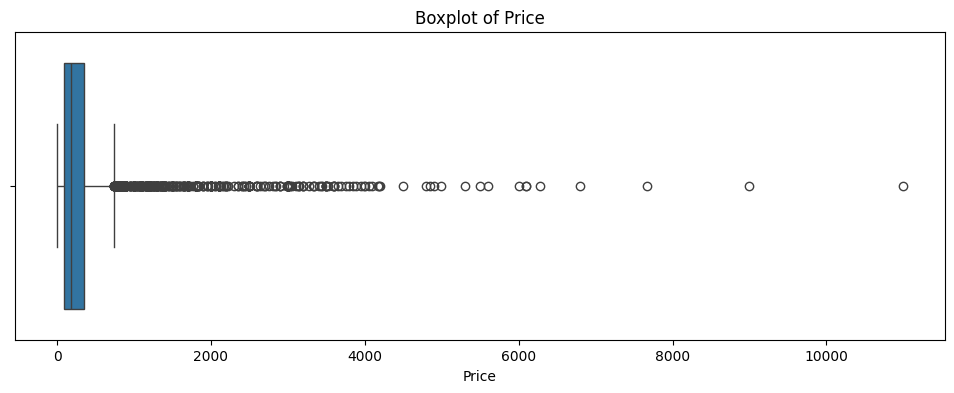

Distribution of DiscountedPrice


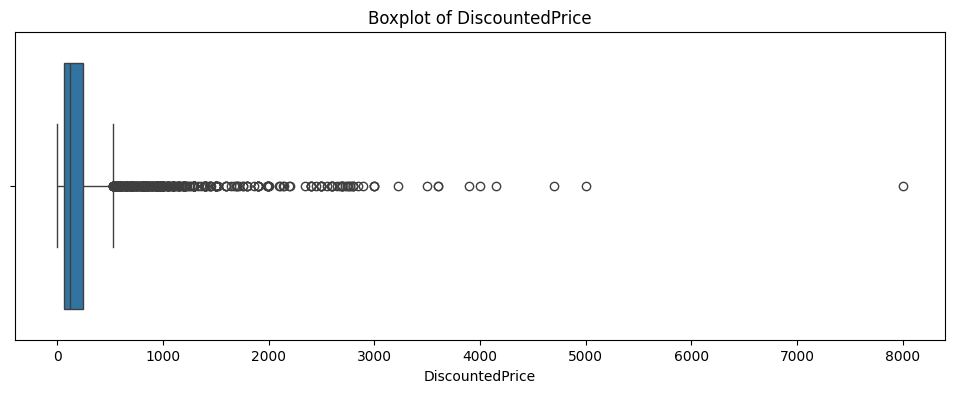

Distribution of DiscountPercent


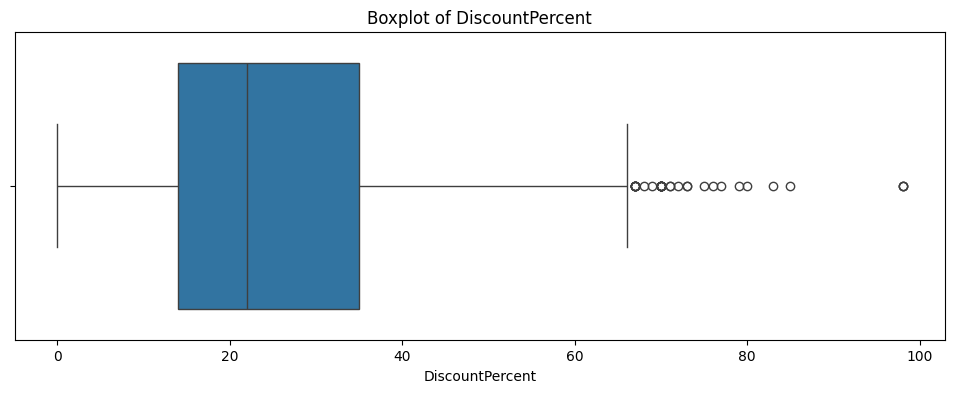

In [ ]:
cols = ["Price", "DiscountedPrice", "DiscountPercent"]

for col in cols:
    print("Distribution of", col)

    plt.figure(figsize=(12, 4))
    sns.boxplot(x=clean_data[col].dropna())

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

Distribution of Price


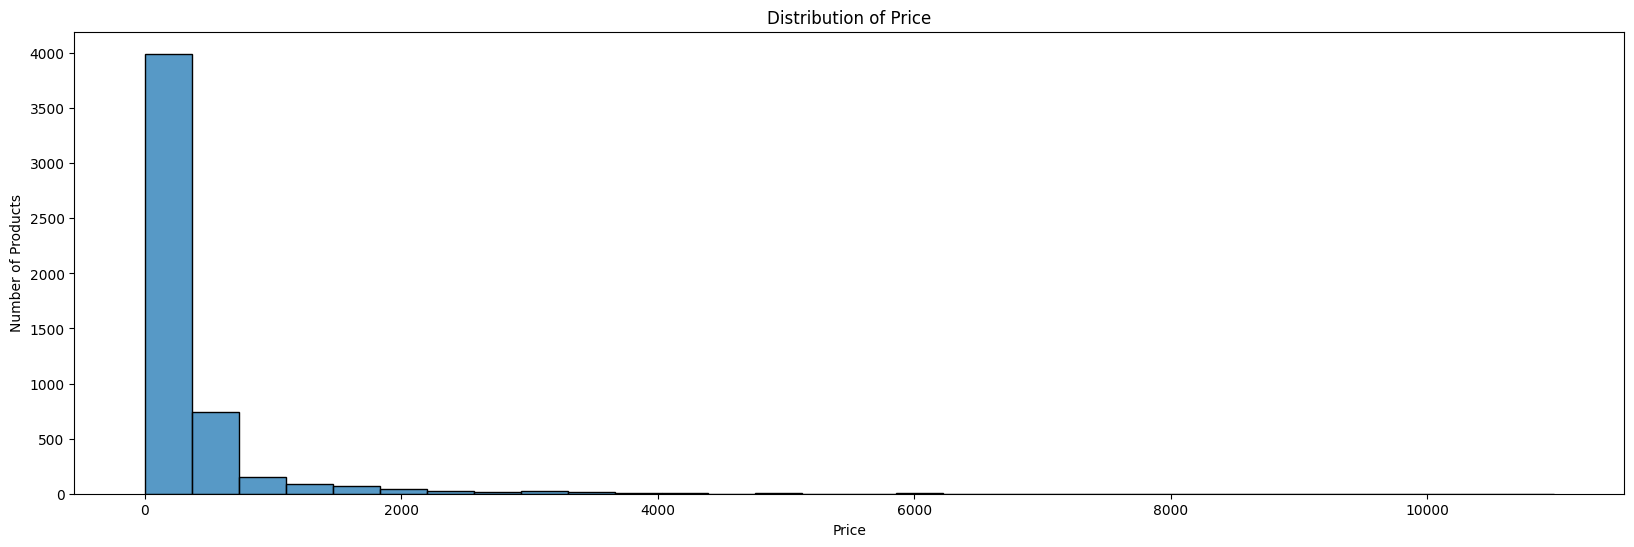

Distribution of DiscountedPrice


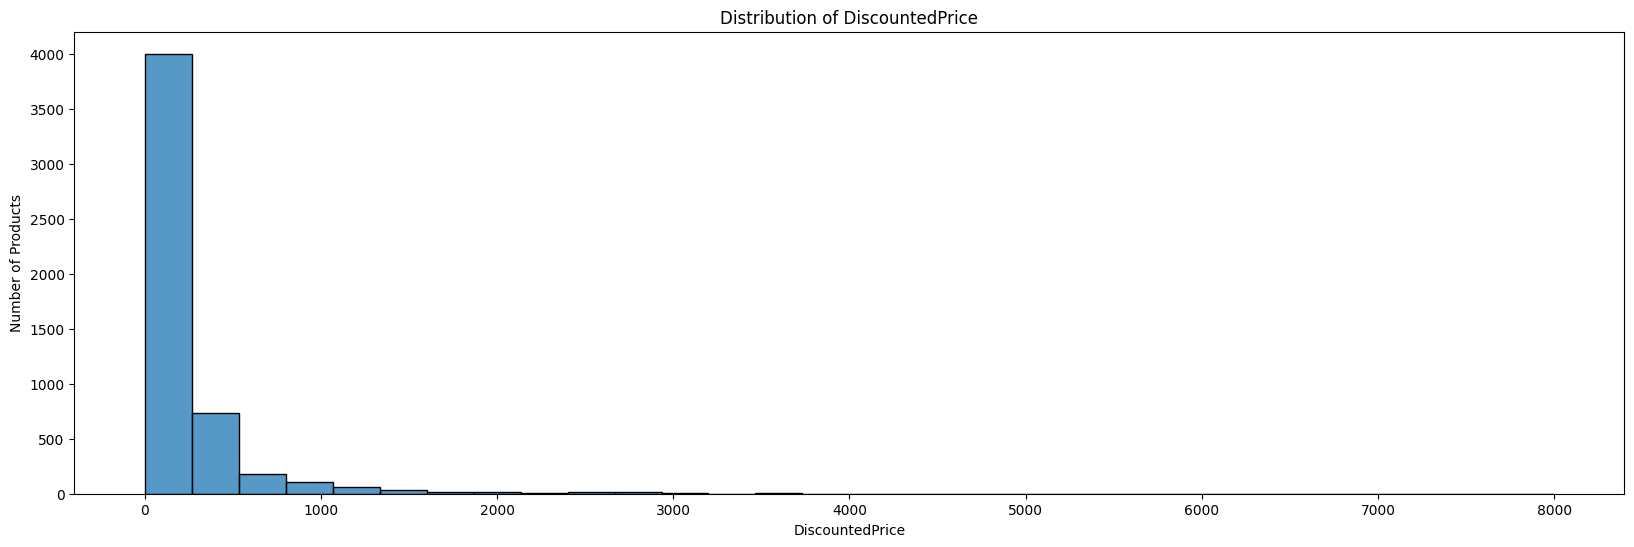

Distribution of DiscountPercent


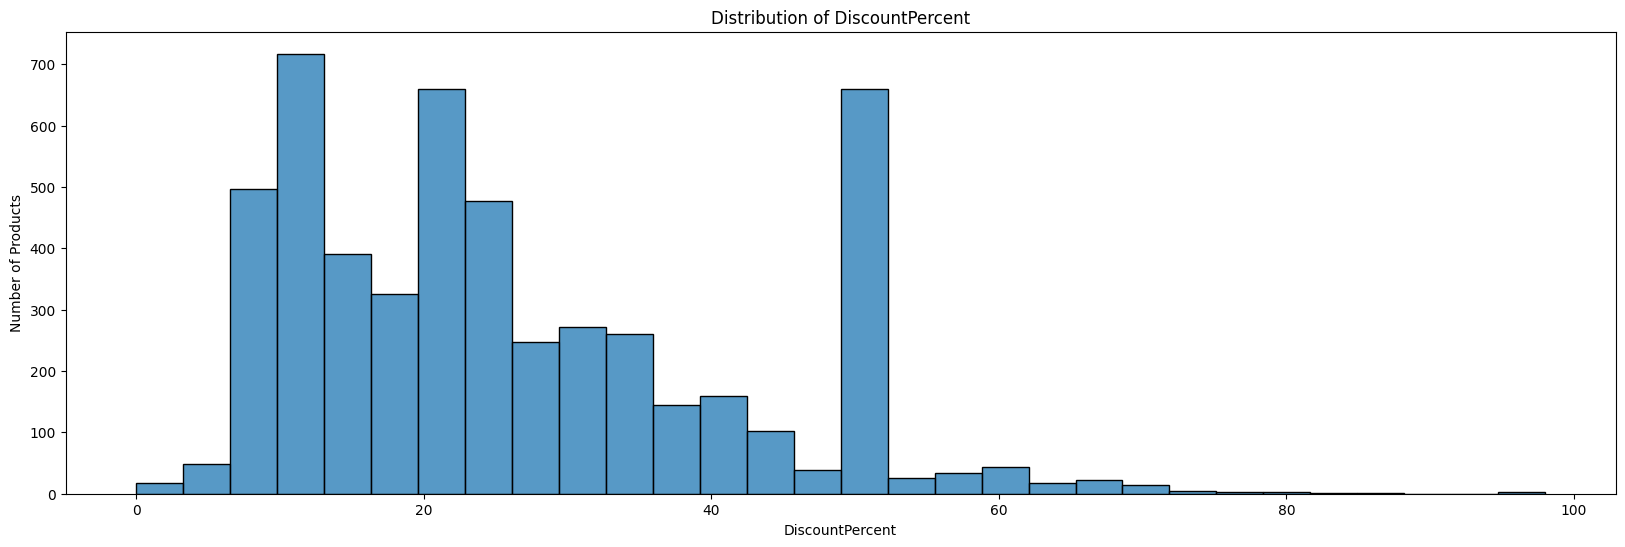

In [ ]:
cols = ["Price", "DiscountedPrice", "DiscountPercent"]

for i in cols:
    print("Distribution of", i)

    plt.figure(figsize=(20, 6))
    sns.histplot(data=clean_data, x=i, bins=30)

    plt.title(f"Distribution of {i}")
    plt.xlabel(i)
    plt.ylabel("Number of Products")
    plt.show()

In [ ]:
cols = ["Price", "DiscountedPrice", "DiscountPercent"]

for col in cols:
    Q1 = clean_data[col].quantile(0.25)
    Q3 = clean_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = clean_data[
        (clean_data[col] < lower_limit) |
        (clean_data[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Potential outliers:", len(outliers))


Column: Price
Q1: 85.0
Q3: 345.0
IQR: 260.0
Lower limit: -305.0
Upper limit: 735.0
Potential outliers: 455

Column: DiscountedPrice
Q1: 64.0
Q3: 249.0
IQR: 185.0
Lower limit: -213.5
Upper limit: 526.5
Potential outliers: 460

Column: DiscountPercent
Q1: 14.0
Q3: 35.0
IQR: 21.0
Lower limit: -17.5
Upper limit: 66.5
Potential outliers: 37


In [ ]:
clean_data.to_csv("/content/DMart_Cleaned.csv", index=False)
print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


**Detailed EDA**

In [ ]:
eda_data = clean_data.copy()

In [ ]:
eda_data.Category.value_counts()

,count
Category,
Personal Care,1234
Packaged Food,1125
Home & Kitchen,880
Grocery,840
Dairy & Beverages,429
Specials,187
Clothing & Accessories,97
Fruits & Vegetables,78
School Supplies,69


In [ ]:
eda_data[
    (eda_data["Category"] == "Wonderchef") |
    (eda_data["Category"] == "Syska") |
    (eda_data["Category"] == "Butterfly") |
    (eda_data["Category"] == "Pigeon") |
    (eda_data["Category"] == "Zebronics") |
    (eda_data["Category"] == "Geep") |
    (eda_data["Category"] == "Joyo Plastics")
]

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
2934,Wonderchef Nutri-Blend Black,Wonderchef,5300.0,2699.0,Wonderchef,Wonderchef,400 W,\n- The 400W superfast motor blends & grinds i...,Wonderchef,49
3156,Butterfly Stainless Steel Outer Lid Curve Cooker,Butterfly,4851.0,1999.0,Butterfly,Butterfly,5.5 L,Key Features\n- Material: Stainless Steel\n- C...,Butterfly,58
3157,Butterfly Stainless Steel Outer Lid Curve Cooker,Butterfly,3646.0,1599.0,Butterfly,Butterfly,3 L,\n- Induction Base : Yes\n\nKey Features:\n- M...,Butterfly,56
3297,Joyo Kitchen Storewell Container Printed - Ass...,Joyo Plastics,1265.0,449.0,Joyo Plastics,Joyo Plastics,Pack of 3,"\n- Colour : Blue , Pink\n- Capacity : 6.3 Lit...",Joyo Plastics,64
3298,Joyo Kitchen Storewell Container Printed - Ass...,Joyo Plastics,550.0,499.0,Joyo Plastics,Joyo Plastics,Pack of 4,"\n- Colour : Blue , Pink\n- Capacity : 6.3 Lit...",Joyo Plastics,9
3460,Geep Extreme 3 PIN Multi Plug Adapter,Geep,205.0,99.0,Geep,Geep,1 U,\n- Brand : Geep\n- Type : Three Pin Plug\n- C...,Geep,51
3462,Geep Micro USB High Speed Charging Cable (1 Me...,Geep,299.0,49.0,Geep,Geep,1 U,\n- Code : Geep USB 001\n- Dimensions : 200 X ...,Geep,83
3463,Geep G-Square Flex Box,Geep,360.0,179.0,Geep,Geep,4 m,\n- Brand : Geep\n- Model No : GPFB 4 MS\n- So...,Geep,50
3464,Zebronics TU240C Type C Charging Cable,Zebronics,349.0,99.0,Zebronics,Zebronics,1 U,\n- USB to type C cable\n- Supports upto 2.4A\...,Zebronics,71
4754,Syska SDI07 Dry Iron,Syska,799.0,449.0,Syska,Syska,1000 W,Specifications : \n- Voltage : 230V - 50Hz\n- ...,Syska,43


In [ ]:
eda_data['Category'] = eda_data['Category'].replace({'Zebronics':'Appliances','Geep':'Appliances','Syska':'Home & Kitchen','Butterfly':'Home & Kitchen','Wonderchef':'Home & Kitchen','Joyo Plastics':'Home & Kitchen','Pigeon':'Home & Kitchen'})

In [ ]:
eda_data.Category.value_counts()

,count
Category,
Personal Care,1234
Packaged Food,1125
Home & Kitchen,887
Grocery,840
Dairy & Beverages,429
Specials,187
Clothing & Accessories,97
Fruits & Vegetables,78
School Supplies,69


,Category,Product_Count
0,Personal Care,1234
1,Packaged Food,1125
2,Home & Kitchen,887
3,Grocery,840
4,Dairy & Beverages,429
5,Specials,187
6,Clothing & Accessories,97
7,Fruits & Vegetables,78
8,School Supplies,69
9,Appliances,61


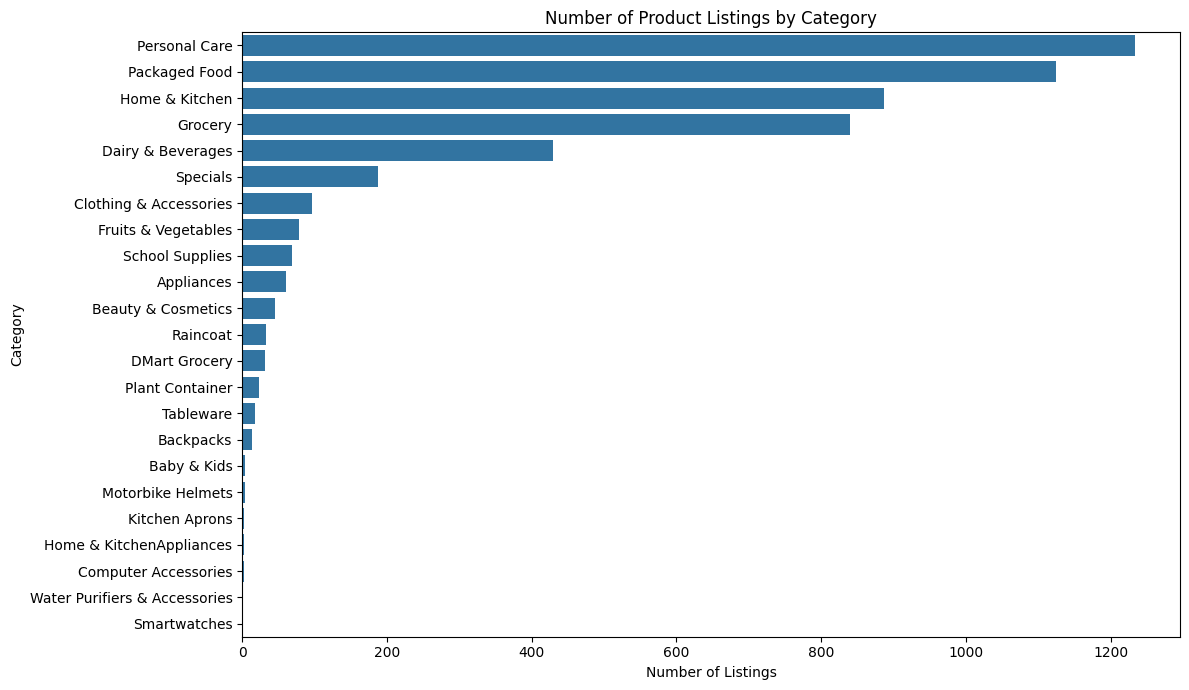

In [ ]:
category_counts = (
    eda_data["Category"]
    .value_counts()
    .rename_axis("Category")
    .reset_index(name="Product_Count")
)

display(category_counts)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=category_counts,
    x="Product_Count",
    y="Category"
)

plt.title("Number of Product Listings by Category")
plt.xlabel("Number of Listings")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

,Brand,Product_Count
0,Local/Unknown,400
1,Premia,155
2,Faces Canada,99
3,Insight,82
4,Amul,79
5,Lakme,74
6,Satyam,68
7,Gillette,44
8,Britannia,42
9,Lotus,40


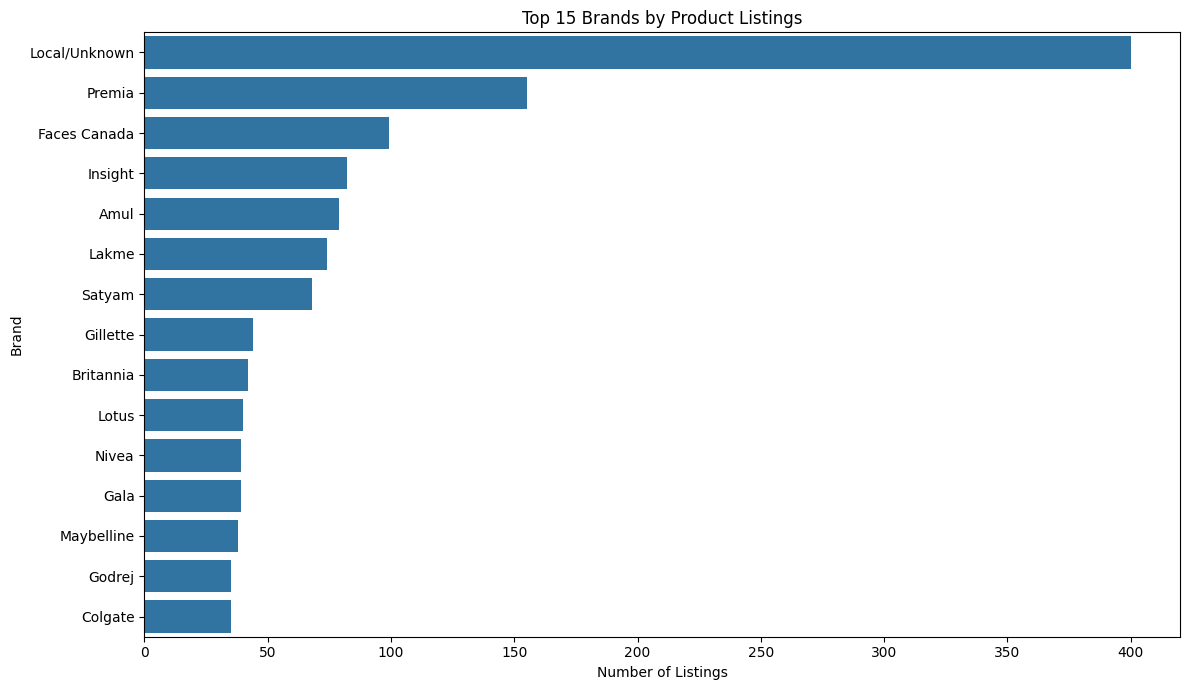

In [ ]:
brand_counts = (
    eda_data["Brand"]
    .fillna("Unknown")
    .value_counts()
    .head(15)
    .rename_axis("Brand")
    .reset_index(name="Product_Count")
)

display(brand_counts)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=brand_counts,
    x="Product_Count",
    y="Brand"
)

plt.title("Top 15 Brands by Product Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

,SubCategory,Product_Count
0,Snacks & Farsans,302
1,Masala & Spices,297
2,Beverages,282
3,Skin Care,257
4,Face Care,174
5,Hair Care,160
6,Specials,157
7,Bed & Bath,150
8,Dairy,147
9,Packaged Food,135


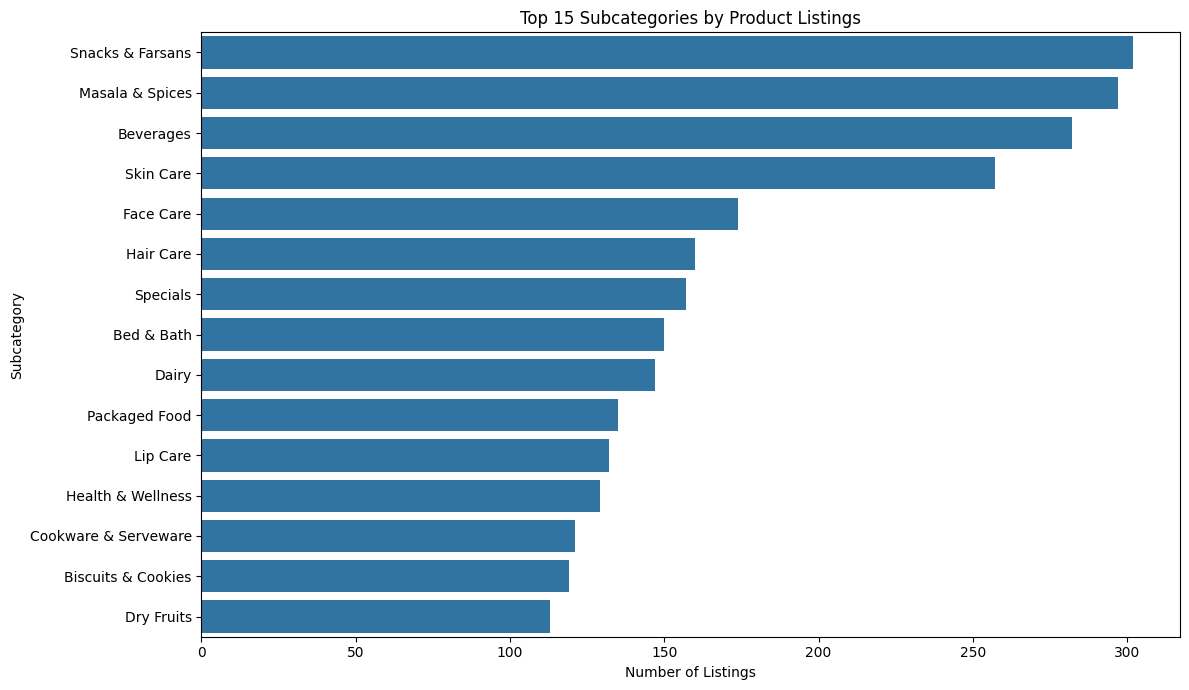

In [ ]:
subcategory_counts = (
    eda_data["SubCategory"]
    .fillna("Unknown")
    .value_counts()
    .head(15)
    .rename_axis("SubCategory")
    .reset_index(name="Product_Count")
)

display(subcategory_counts)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=subcategory_counts,
    x="Product_Count",
    y="SubCategory"
)

plt.title("Top 15 Subcategories by Product Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Subcategory")
plt.tight_layout()
plt.show()

,Quantity,Product_Count
0,1 U,492
1,500 gm,342
2,200 gm,293
3,100 gm,277
4,1 kg,198
5,1 L,182
6,50 gm,127
7,250 gm,104
8,400 gm,100
9,150 gm,88


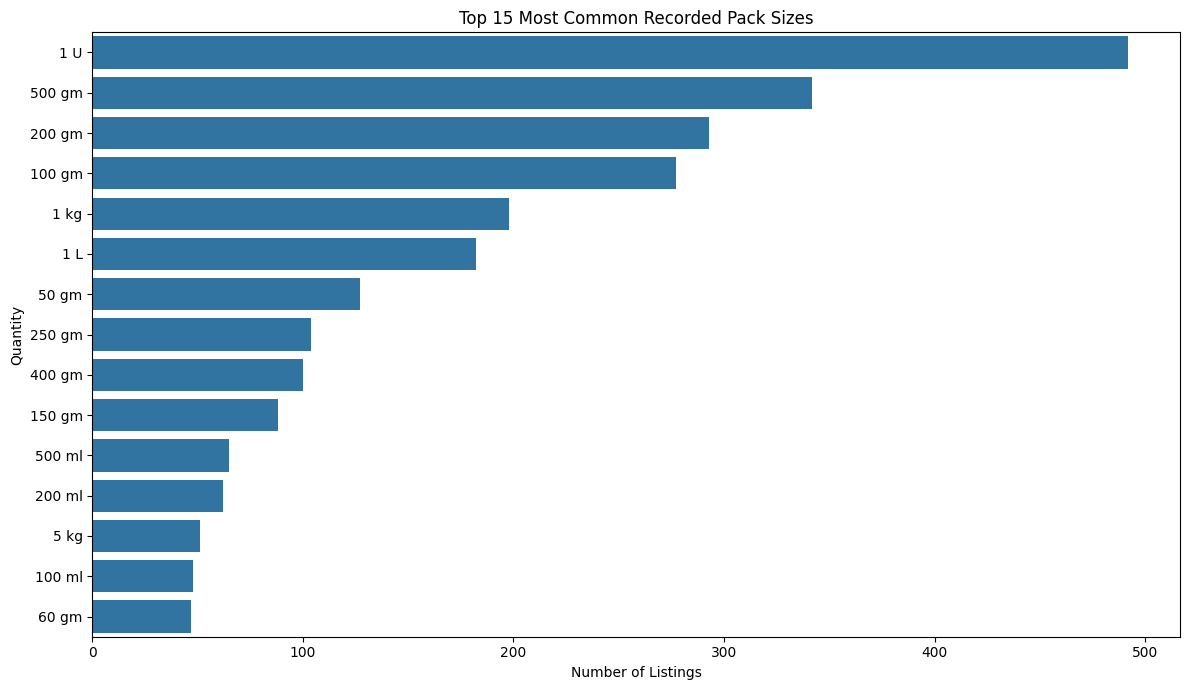

In [ ]:
quantity_counts = (
    eda_data["Quantity"]
    .fillna("Unknown")
    .value_counts()
    .head(15)
    .rename_axis("Quantity")
    .reset_index(name="Product_Count")
)

display(quantity_counts)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=quantity_counts,
    x="Product_Count",
    y="Quantity"
)

plt.title("Top 15 Most Common Recorded Pack Sizes")
plt.xlabel("Number of Listings")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

Text(0, 0.5, 'Number of Products')

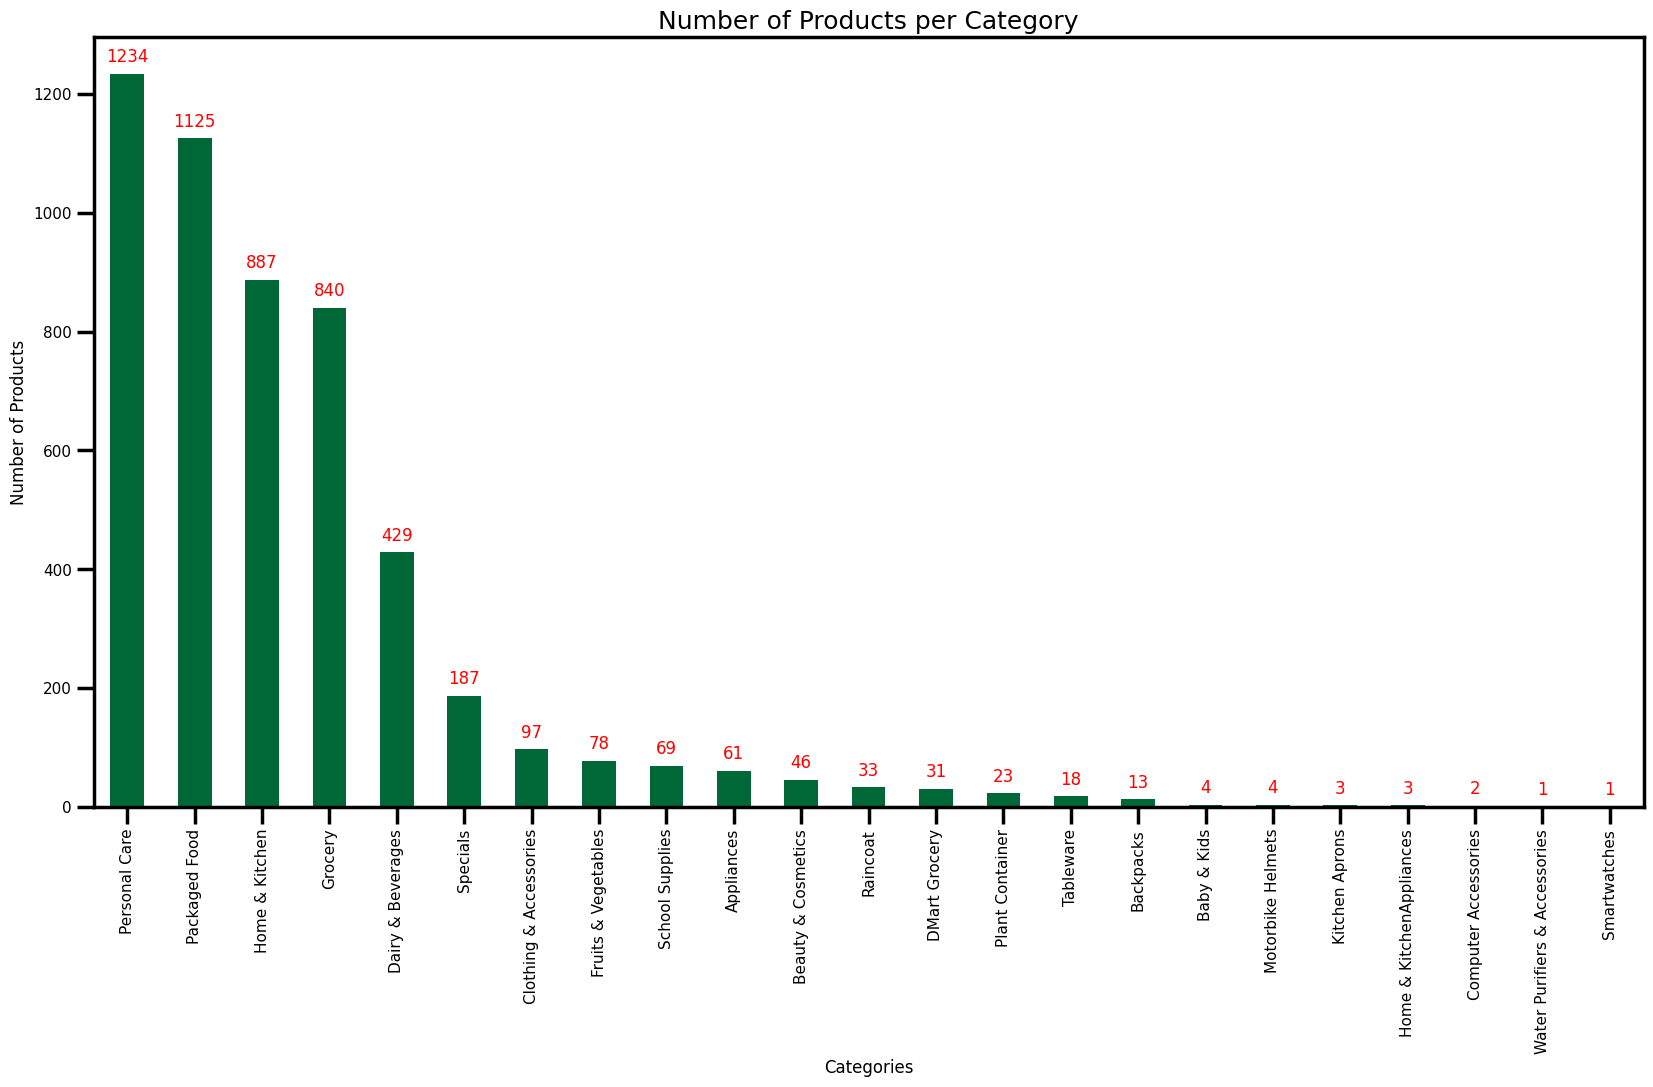

In [ ]:
sns.set_context("poster",font_scale=0.5)
plt.figure(figsize=(20,10))
ax = eda_data.Category.value_counts().plot(kind='bar',cmap='RdYlGn_r')

for p in ax.patches:
    ax.annotate(int(p.get_height()),(p.get_x()+0.25,p.get_height()+20),ha='center',color='red')

plt.title('Number of Products per Category',fontsize=18)
plt.xlabel('Categories')
plt.ylabel('Number of Products')

In [ ]:
eda_data['SubCategory']=eda_data['SubCategory'].replace({'Zebronics':'Appliances','Geep':'Appliances','Syska':'Home Appliances','Butterfly':'Kitchen Appliances','Wonderchef':'Kitchen Appliances','Joyo Plastics':'Kitchen Appliances','Pigeon':'Kitchen Appliances'})

In [ ]:
eda_data.SubCategory.value_counts()

,count
SubCategory,
Snacks & Farsans,302
Masala & Spices,297
Beverages,282
Skin Care,257
Face Care,174
...,...
Motorbike Helmets,4
Kitchen Aprons,3
Computer Accessories,2


In [ ]:
eda_data.groupby("Category")[['SubCategory','Brand','Name']].nunique().rename(columns={"Name":'Number of Products'})

,SubCategory,Brand,Number of Products
Category,,,
Appliances,3,20,60
Baby & Kids,1,2,4
Backpacks,1,5,13
Beauty & Cosmetics,2,11,42
Clothing & Accessories,2,9,42
Computer Accessories,1,1,2
DMart Grocery,2,3,21
Dairy & Beverages,2,106,338
Fruits & Vegetables,1,3,76


In [ ]:
#Avg Discount on Each Category

eda_data.DiscountPercent.mean()

np.float64(26.016958951628446)

In [ ]:
eda_data.groupby('Category')['DiscountPercent'].mean().sort_values(ascending=False)

,DiscountPercent
Category,
Smartwatches,58.000000
Backpacks,51.461538
Home & KitchenAppliances,49.666667
Computer Accessories,37.500000
Appliances,34.672131
Specials,32.326203
Clothing & Accessories,32.123711
Plant Container,30.521739
Beauty & Cosmetics,28.891304


In [ ]:
#Comparison Between Dmart Groceries and Other Groceries

eda_data[eda_data['Category']=='DMart Grocery']

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
559,Basmati Rice Mogra,Local/Unknown,375.0,289.0,DMart Grocery,Rice & Rice Products,5 kg,IngredientsRiceStorage ConditionStore in a coo...,Rice & Rice Products,22
560,Basmati Rice Mogra,Local/Unknown,750.0,549.0,DMart Grocery,Rice & Rice Products,10 kg,Basmati Rice is classified according to its gr...,Rice & Rice Products,26
566,Rice Pulav Basmati,Local/Unknown,500.0,398.0,DMart Grocery,Rice & Rice Products,5 kg,"StorageStore in a cool, dry, and hygienic plac...",Rice & Rice Products,20
569,Basmati Rice Mini Mogra (Broken),Local/Unknown,650.0,440.0,DMart Grocery,Rice & Rice Products,10 kg,IngredientsRiceBasmati Rice is classified acco...,Rice & Rice Products,32
575,Rice Basmati,Local/Unknown,140.0,115.0,DMart Grocery,Rice & Rice Products,1 kg,Basmati Rice is classified according to its gr...,Rice & Rice Products,17
585,Biryani Rice,Local/Unknown,700.0,505.0,DMart Grocery,Rice & Rice Products,5 kg,IngredientsRiceBasmati Rice is classified acco...,Rice & Rice Products,27
588,Rice Tibar Basmati,Local/Unknown,650.0,452.0,DMart Grocery,Rice & Rice Products,5 kg,"StorageStore in a cool, dry and hygienic place...",Rice & Rice Products,30
595,Rice Basmati Wand : 5 kgs,Local/Unknown,800.0,526.0,DMart Grocery,Rice & Rice Products,5 kg,IngredientsRiceStorageStore in a cool and dry ...,Rice & Rice Products,34
597,Mogra Basmati Rice,Local/Unknown,72.0,61.0,DMart Grocery,Rice & Rice Products,1 kg,OverviewThe fine long grains and the aromatic ...,Rice & Rice Products,15
605,Wada Kolam Rice,Local/Unknown,850.0,615.0,DMart Grocery,Rice & Rice Products,10 kg,"IngredientsRiceStorageStore in a cool, dry, an...",Rice & Rice Products,27


In [ ]:
#We will Compare the Rice & Rice Products for Dmart Grceries and normal Groceries


gro_Rice = eda_data[(eda_data['Category']=='Grocery')&(eda_data['SubCategory']=='Rice & Rice Products')]
gro_Rice

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
237,Premia Poha Jada,Premia,64.0,52.0,Grocery,Rice & Rice Products,1 kg,IngredientsRice FlakesStorageStore in a cool a...,Rice & Rice Products,18
238,Premia Poha Jada,Premia,33.0,27.0,Grocery,Rice & Rice Products,500 gm,India,Rice & Rice Products,18
265,Mamra (Puffed Rice),Local/Unknown,60.0,40.0,Grocery,Rice & Rice Products,500 gm,Key Features - Well Cleaned - Healthy and Tast...,Rice & Rice Products,33
282,Premia Poha Patla,Premia,37.0,30.0,Grocery,Rice & Rice Products,500 gm,IngredientsRice FlakesStorageStore in a cool a...,Rice & Rice Products,18
295,Premia Poha Basmati,Premia,57.0,47.0,Grocery,Rice & Rice Products,500 gm,IngredientsRice FlakesStorageStore in a cool a...,Rice & Rice Products,17
...,...,...,...,...,...,...,...,...,...,...
626,Red Rice,Local/Unknown,67.0,51.0,Grocery,Rice & Rice Products,1 kg,India,Rice & Rice Products,23
627,Long Grain Rice,Local/Unknown,650.0,470.0,Grocery,Rice & Rice Products,10 kg,"Overview:High quality, long-grained rice to ma...",Rice & Rice Products,27
628,IR Boiled Rice,Local/Unknown,44.0,41.0,Grocery,Rice & Rice Products,1 kg,India,Rice & Rice Products,6
629,Masoori Boiled Rice,Local/Unknown,51.0,42.0,Grocery,Rice & Rice Products,1 kg,"Overview:An everyday rice, masoori boiled rice...",Rice & Rice Products,17


In [ ]:
DMart_gro_Rice = eda_data[(eda_data['Category']=='DMart Grocery')&(eda_data['SubCategory']=='Rice & Rice Products')]
DMart_gro_Rice

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
559,Basmati Rice Mogra,Local/Unknown,375.0,289.0,DMart Grocery,Rice & Rice Products,5 kg,IngredientsRiceStorage ConditionStore in a coo...,Rice & Rice Products,22
560,Basmati Rice Mogra,Local/Unknown,750.0,549.0,DMart Grocery,Rice & Rice Products,10 kg,Basmati Rice is classified according to its gr...,Rice & Rice Products,26
566,Rice Pulav Basmati,Local/Unknown,500.0,398.0,DMart Grocery,Rice & Rice Products,5 kg,"StorageStore in a cool, dry, and hygienic plac...",Rice & Rice Products,20
569,Basmati Rice Mini Mogra (Broken),Local/Unknown,650.0,440.0,DMart Grocery,Rice & Rice Products,10 kg,IngredientsRiceBasmati Rice is classified acco...,Rice & Rice Products,32
575,Rice Basmati,Local/Unknown,140.0,115.0,DMart Grocery,Rice & Rice Products,1 kg,Basmati Rice is classified according to its gr...,Rice & Rice Products,17
585,Biryani Rice,Local/Unknown,700.0,505.0,DMart Grocery,Rice & Rice Products,5 kg,IngredientsRiceBasmati Rice is classified acco...,Rice & Rice Products,27
588,Rice Tibar Basmati,Local/Unknown,650.0,452.0,DMart Grocery,Rice & Rice Products,5 kg,"StorageStore in a cool, dry and hygienic place...",Rice & Rice Products,30
595,Rice Basmati Wand : 5 kgs,Local/Unknown,800.0,526.0,DMart Grocery,Rice & Rice Products,5 kg,IngredientsRiceStorageStore in a cool and dry ...,Rice & Rice Products,34
597,Mogra Basmati Rice,Local/Unknown,72.0,61.0,DMart Grocery,Rice & Rice Products,1 kg,OverviewThe fine long grains and the aromatic ...,Rice & Rice Products,15
605,Wada Kolam Rice,Local/Unknown,850.0,615.0,DMart Grocery,Rice & Rice Products,10 kg,"IngredientsRiceStorageStore in a cool, dry, an...",Rice & Rice Products,27


In [ ]:
print('DMart Rice avg Price', int(DMart_gro_Rice.Price.mean()))
print('Other Rice avg Price', int(gro_Rice.Price.mean()))

print('DMart Rice avg Discount', int(DMart_gro_Rice.DiscountPercent.mean()))
print('Other Rice avg Discount', int(gro_Rice.DiscountPercent.mean()))

DMart Rice avg Price 437
Other Rice avg Price 348
DMart Rice avg Discount 24
Other Rice avg Discount 22


In [ ]:
#Clothing Category

clothing = eda_data[eda_data['Category']=='Clothing & Accessories']

In [ ]:
clothing.SubCategory.value_counts()

,count
SubCategory,
Men's,50
Women's,47


In [ ]:
px.pie(values= clothing.SubCategory.value_counts().values,names =clothing.SubCategory.value_counts().index,hole=0.6)

In [ ]:
clothing.groupby('SubCategory')['DiscountPercent'].mean()


,DiscountPercent
SubCategory,
Men's,23.680000
Women's,41.106383


Text(0, 0.5, 'Avg.DiscountedPrice')

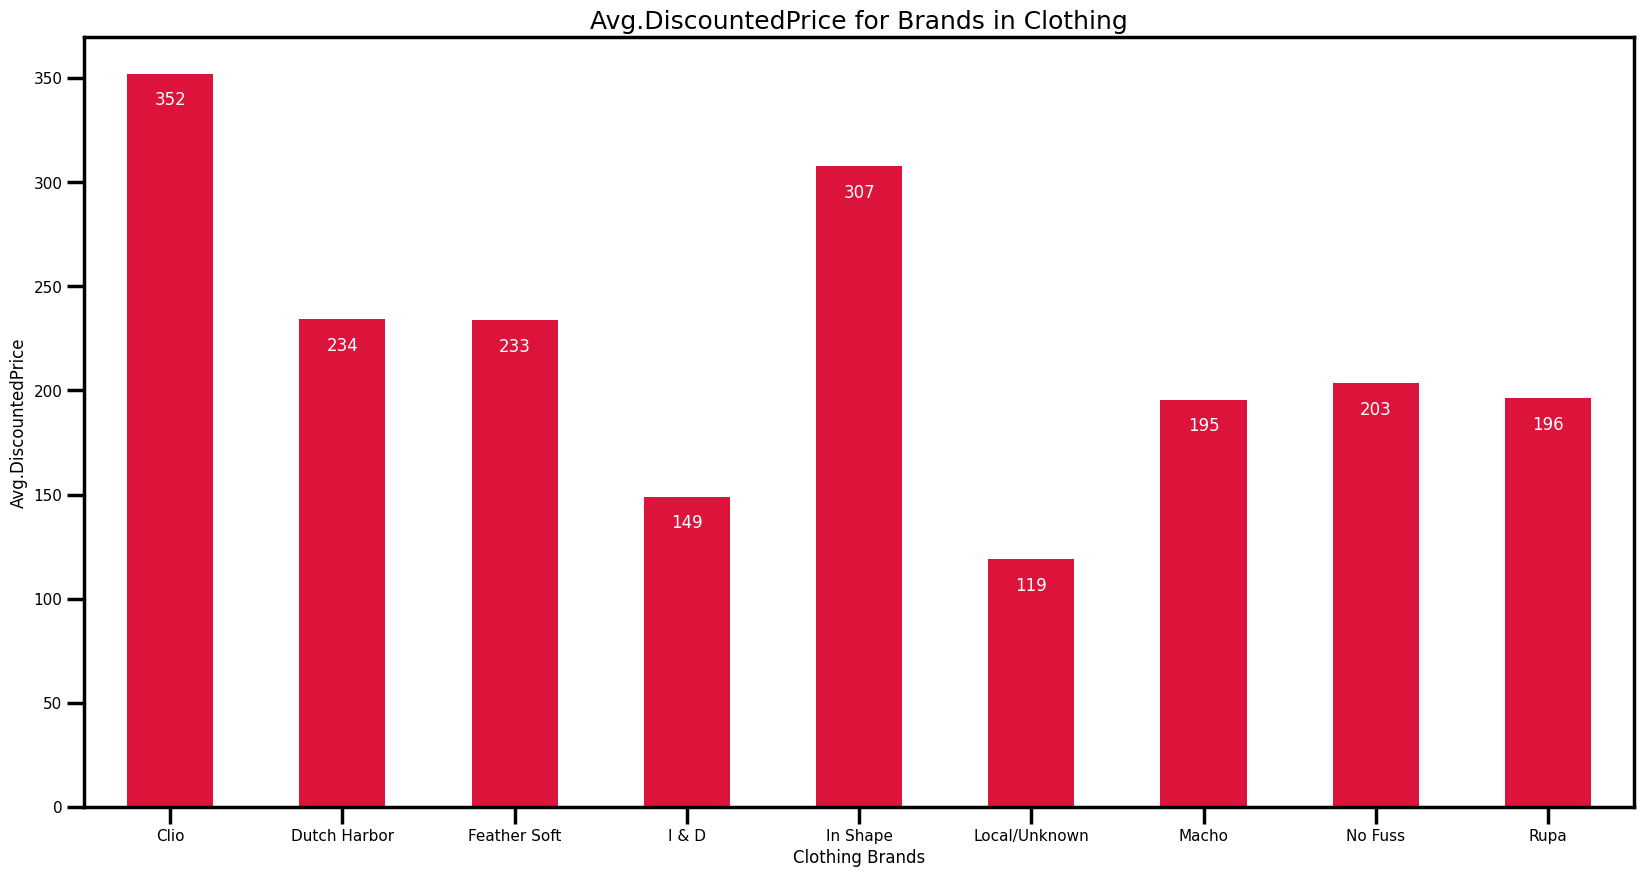

In [ ]:
sns.set_context("poster",font_scale=0.5)
plt.figure(figsize=(20,10))
ax = clothing.groupby('Brand')['DiscountedPrice'].mean().plot(kind='bar',color='crimson',rot=0)

for p in ax.patches:
    ax.annotate(int(p.get_height()),(p.get_x()+0.25,p.get_height()-15),ha='center',color='white')

plt.title('Avg.DiscountedPrice for Brands in Clothing',fontsize=18)
plt.xlabel('Clothing Brands')
plt.ylabel('Avg.DiscountedPrice')

In [ ]:
cloth_brand_mean = clothing.groupby(['Brand','SubCategory'])['DiscountedPrice'].mean().reset_index()
cloth_brand_mean

,Brand,SubCategory,DiscountedPrice
0,Clio,Women's,352.125000
1,Dutch Harbor,Men's,234.200000
2,Feather Soft,Women's,233.782609
3,I & D,Men's,149.000000
4,In Shape,Women's,307.666667
5,Local/Unknown,Men's,119.000000
6,Macho,Men's,195.562500
7,No Fuss,Men's,215.950000
8,No Fuss,Women's,79.000000
9,Rupa,Men's,196.166667


In [ ]:
#Women Clothing with more than 50% discount

clothing[(clothing['SubCategory']=="Women's")&(clothing['DiscountPercent']>50)]

,Name,Brand,Price,DiscountedPrice,Category,SubCategory,Quantity,Description,BreadCrumbs,DiscountPercent
4858,Feather Soft Navy Blue Ankle Length Legging - ...,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size M,\n- Brand Name : Feather Soft\n- Colour : Navy...,Women's,70
4859,Feather Soft Navy Blue Ankle Length Legging - ...,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size L,\n- Brand Name : Feather Soft\n- Colour : Navy...,Women's,70
4862,Feather Soft Red Ankle Length Legging - 1 Unit,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size M,\n- Brand Name : Feather Soft\n- Colour : Red\...,Women's,70
4863,Feather Soft Red Ankle Length Legging - 1 Unit,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size L,\n- Brand Name : Feather Soft\n- Colour : Red\...,Women's,70
4865,Feather Soft Red Ankle Length Legging - 1 Unit,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size XXL,\n- Brand Name : Feather Soft\n- Colour : Red\...,Women's,70
4866,Feather Soft Skin Color Ankle Length Legging -...,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size M,\n- Brand Name : Feather Soft\n- Colour : Skin...,Women's,70
4867,Feather Soft Skin Color Ankle Length Legging -...,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size L,\n- Brand Name : Feather Soft\n- Colour : Skin...,Women's,70
4868,Feather Soft Skin Color Ankle Length Legging -...,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size XL,\n- Brand Name : Feather Soft\n- Colour : Skin...,Women's,70
4869,Feather Soft Skin Color Ankle Length Legging -...,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size XXL,\n- Brand Name : Feather Soft\n- Colour : Skin...,Women's,70
4870,Feather Soft Skin Color Ankle Length Legging -...,Feather Soft,499.0,149.0,Clothing & Accessories,Women's,Size XXXL,Unique Features :Skin friendly magical soft to...,Women's,70


In [ ]:
eda_data[eda_data['Category']=='Personal Care'].groupby(['SubCategory','Brand'])['Name'].count().reset_index()


,SubCategory,Brand,Name
0,Baby & Kids,Friends,4
1,Baby & Kids,Himalaya,11
2,Baby & Kids,Huggies,9
3,Baby & Kids,Johnson's,5
4,Baby & Kids,Little's,1
...,...,...,...
246,Skin Care,Yardley,2
247,Tissue Paper & Napkins,Cleanplus,1
248,Tissue Paper & Napkins,Fresh Ones,1
249,Tissue Paper & Napkins,Origami,3


In [ ]:
eda_data[eda_data['Category']=='Personal Care'].groupby('SubCategory')[['Brand','Name']].nunique().sort_values(by='Name',ascending=False).rename(columns={'Name':'No.of.Products'})


,Brand,No.of.Products
SubCategory,,
Skin Care,57,194
Face Care,26,155
Lip Care,8,132
Hair Care,39,124
Health & Wellness,47,104
Nail Care,4,69
Oral Care,14,57
Deos & Perfumes,13,53
Baby & Kids,10,47
